# 07_03 — Feature selection per day

From the **overall** correlation matrices of `07_02` (`segment_correlations.csv`), per segment:

1. **candidates**: variables with |r with `BCM_GUN`| ≥ `R_MIN`
2. **selection**: go through the candidates from the strongest down; keep one only if its |r| with every
   variable already kept is ≤ `R_CROSS`, otherwise mark it as redundant with the first kept variable it clashes with

One figure per day (day = start date of the run), one panel per segment. Blue = kept, grey = redundant.
Saved to `results/data_labelling/segment_correlations/selection_<day>.png`. Run `07_02` first.

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SEG_DIR = REPO / "results" / "data_labelling" / "segment_correlations"
STITCHED = REPO / "results" / "data_labelling" / "stitched_index.csv"

KIND = "Overall"
R_MIN = 0.25    # |r| with BCM_GUN to be a candidate
R_CROSS = 0.5   # max |r| allowed between kept variables
MIN_SHOTS = 500  # segments with fewer kept shots get a warning in the title

KEPT, DROPPED = "#2a78d6", "#c9c8c3"
INK, MUTED, GRID = "#2b2b29", "#8a8985", "#e6e5e1"

pairs = pd.read_csv(SEG_DIR / "segment_correlations.csv").query("kind == @KIND")
idx = pd.read_csv(STITCHED, usecols=["segment", "run", "chunk"])
segments = idx.groupby("segment").agg(run=("run", "first"), first_chunk=("chunk", "min"), last_chunk=("chunk", "max"))
segments["day"] = segments["run"].str.extract(r"(\d{4}-\d{2}-\d{2})", expand=False)
segments["start"] = segments["run"].str.extract(r"_(\d{2}-\d{2})-\d{2}$", expand=False).str.replace("-", ":")
segments

,run,first_chunk,last_chunk,day,start
segment,,,,,
0,acquisition_2026-10-07_21-43-26,11,71,2026-10-07,21:43
1,acquisition_2026-10-08_00-08-19,0,193,2026-10-08,00:08
2,acquisition_2026-10-08_15-42-27,0,1,2026-10-08,15:42
3,acquisition_2026-10-08_15-42-27,4,74,2026-10-08,15:42
4,acquisition_2026-10-08_15-42-27,76,120,2026-10-08,15:42
5,acquisition_2026-10-08_21-11-47,0,199,2026-10-08,21:11
6,acquisition_2026-10-09_07-46-07,0,40,2026-10-09,07:46
7,acquisition_2026-10-09_07-46-07,87,106,2026-10-09,07:46


In [5]:
def matrix(segment):
    """Full symmetric correlation matrix of one segment from the long table."""
    d = pairs[pairs["segment"] == segment]
    m = d.pivot(index="a", columns="b", values="r")
    names = sorted(set(d["a"]) | set(d["b"]))
    m = m.reindex(index=names, columns=names)
    m = m.fillna(m.T)
    for name in names:
        m.loc[name, name] = 1.0
    return m


def select(m):
    """Greedy selection: candidates by |r with BCM_GUN|, keep if not redundant with an already kept one."""
    vs_bcm = m["BCM_GUN"].drop("BCM_GUN")
    candidates = vs_bcm[vs_bcm.abs() >= R_MIN].sort_values(key=abs, ascending=False)
    rows, kept = [], []
    for name, r in candidates.items():
        clash = next((k for k in kept if abs(m.loc[name, k]) > R_CROSS), None)
        rows.append({"variable": name, "r_bcm": r, "kept": clash is None,
                     "redundant_with": clash, "r_clash": m.loc[name, clash] if clash else np.nan})
        if clash is None:
            kept.append(name)
    return pd.DataFrame(rows)


selection = {k: select(matrix(k)) for k in segments.index if k in pairs["segment"].unique()}
shots = pd.read_csv(SEG_DIR.parent / "stitched_index.csv", usecols=["segment"])["segment"].value_counts()
summary = pd.concat(selection, names=["segment"]).reset_index(level=0)
summary.round(2)

,segment,variable,r_bcm,kept,redundant_with,r_clash
0,0,BTV_amplitude,0.55,True,None,NaN
1,0,lab_laser_power,0.54,True,None,NaN
2,0,BTV_intensity,0.49,False,BTV_amplitude,0.64
3,0,PC1,0.44,False,BTV_amplitude,0.94
0,1,lab_laser_power,0.74,True,None,NaN
1,1,laser_amp,0.57,False,lab_laser_power,0.79
2,1,BTV_intensity,0.44,True,None,NaN
3,1,PGLA_drop,0.40,True,None,NaN
4,1,BTV_amplitude,0.31,False,BTV_intensity,0.85
5,1,PC1,0.26,False,BTV_intensity,0.92


## One figure per day

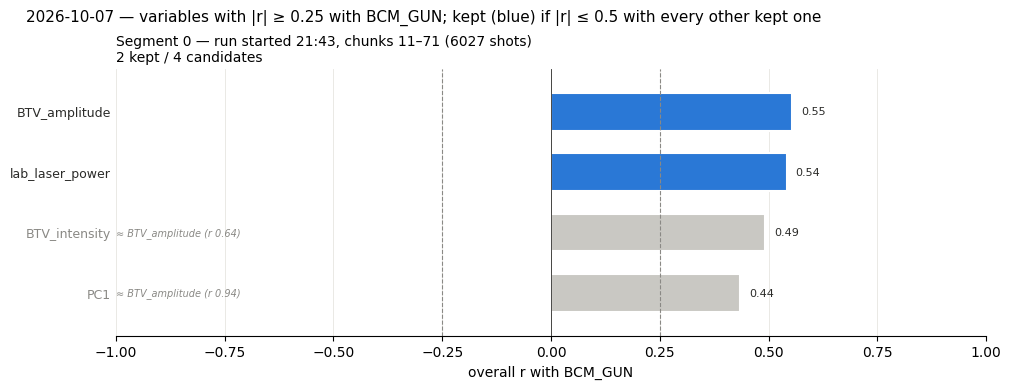

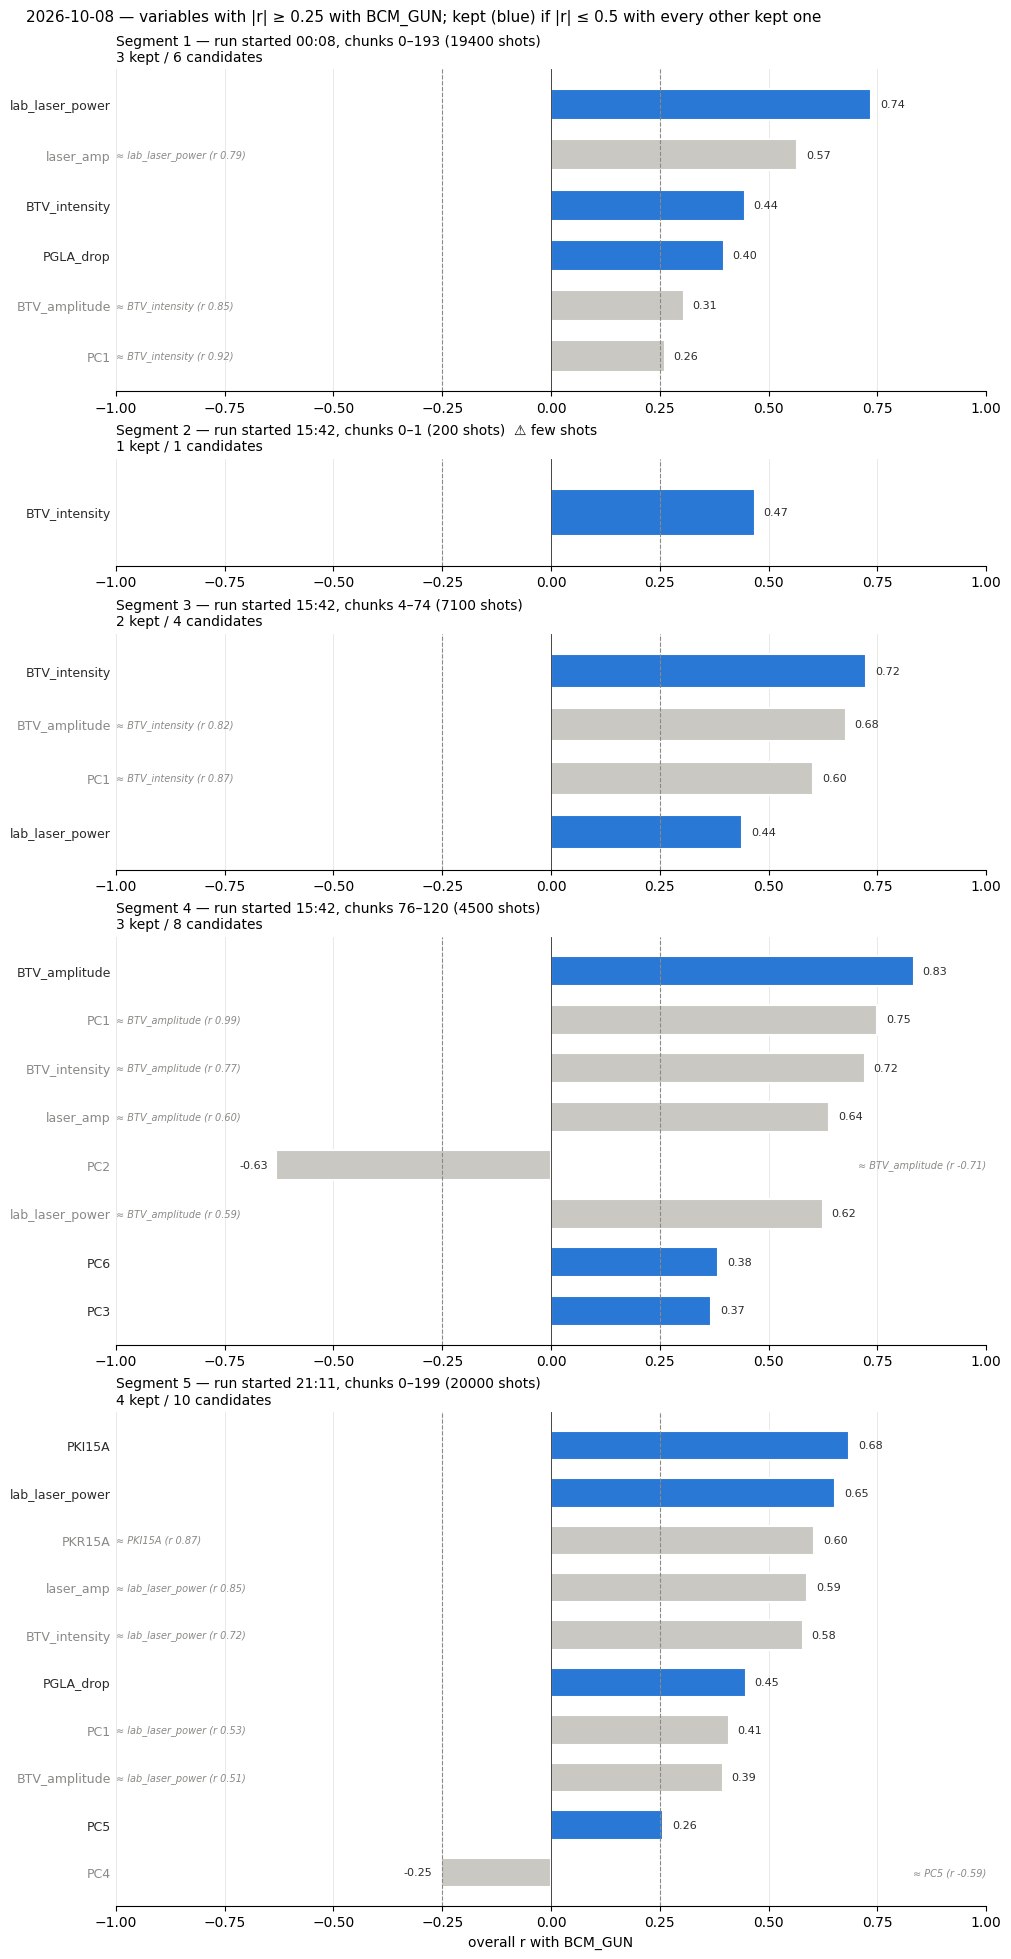

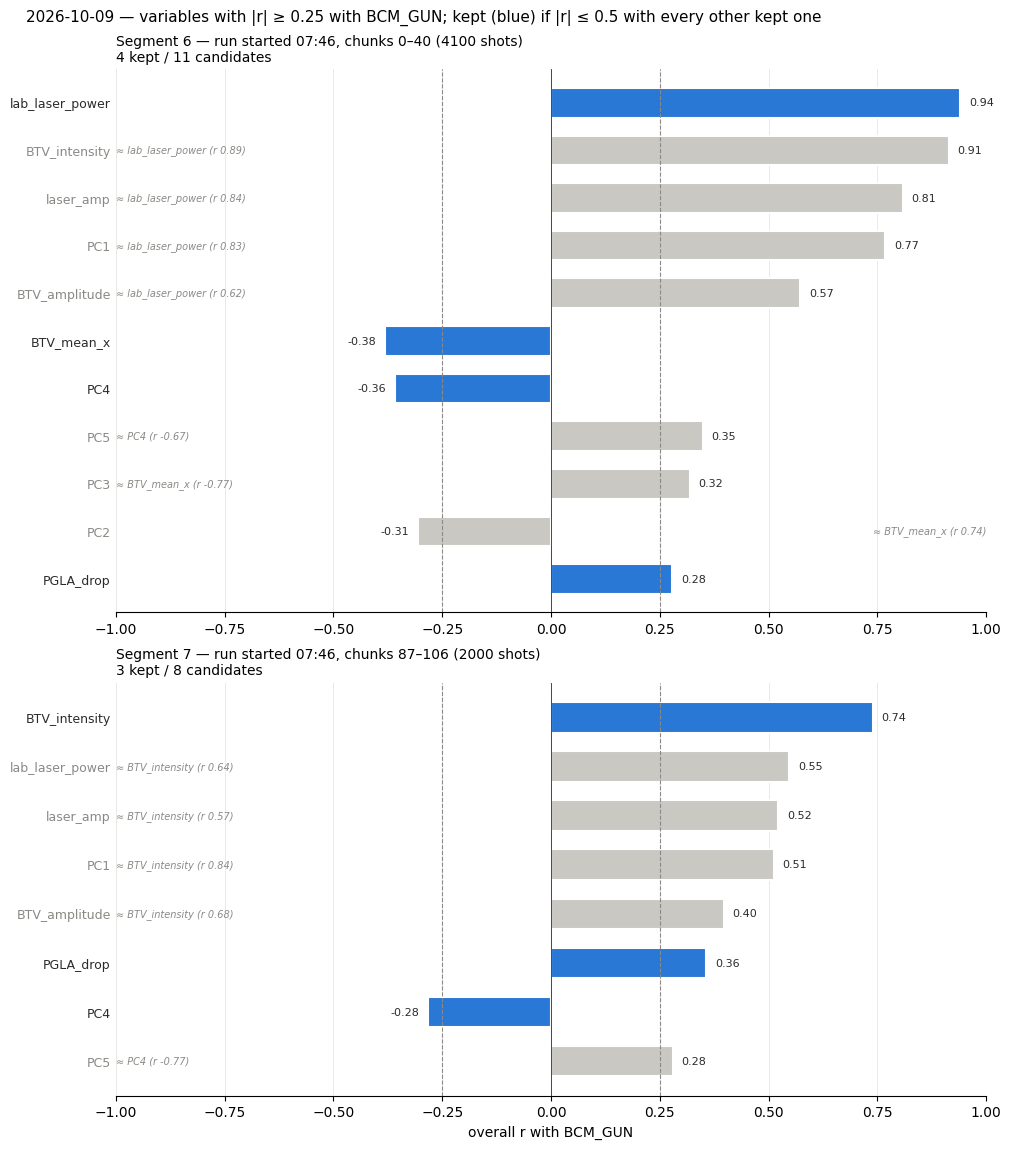

In [6]:
def panel(ax, sel, title):
    sel = sel.iloc[::-1]                       # strongest at the top
    y = np.arange(len(sel))
    colors = [KEPT if k else DROPPED for k in sel["kept"]]
    ax.barh(y, sel["r_bcm"], height=0.62, color=colors, edgecolor="white", linewidth=1.5)
    for yi, (_, row) in zip(y, sel.iterrows()):
        inside = row["r_bcm"] > 0
        ax.text(row["r_bcm"] + (0.02 if inside else -0.02), yi, f"{row['r_bcm']:.2f}",
                va="center", ha="left" if inside else "right", fontsize=8, color=INK)
        if not row["kept"]:
            note = f"≈ {row['redundant_with']} (r {row['r_clash']:.2f})"
            ax.text(-1.0 if inside else 1.0, yi, note, va="center", ha="left" if inside else "right",
                    fontsize=7, color=MUTED, style="italic")
    ax.set_yticks(y, sel["variable"], fontsize=9)
    for yt, k in zip(ax.get_yticklabels(), sel["kept"]):
        yt.set_color(INK if k else MUTED)
    for x in (-R_MIN, R_MIN):
        ax.axvline(x, color=MUTED, lw=0.8, ls="--")
    ax.axvline(0, color=INK, lw=0.6)
    ax.set_xlim(-1, 1)
    ax.set_ylim(-0.7, max(len(sel), 1) - 0.3)
    ax.grid(axis="x", color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.set_title(title, fontsize=10, loc="left")
    for spine in ("top", "right", "left"):
        ax.spines[spine].set_visible(False)
    ax.tick_params(axis="y", length=0)


for day, segs in segments.loc[list(selection)].groupby("day"):
    n = len(segs)
    heights = [max(len(selection[k]), 1) for k in segs.index]
    fig, axes = plt.subplots(n, 1, figsize=(10, 0.42 * sum(heights) + 1.3 * n + 0.8),
                             gridspec_kw={"height_ratios": [h + 1.5 for h in heights]}, squeeze=False,
                             layout="constrained")
    for ax, (k, info) in zip(axes[:, 0], segs.iterrows()):
        sel = selection[k]
        n_kept = int(sel["kept"].sum())
        warn = "  ⚠ few shots" if shots.get(k, 0) < MIN_SHOTS else ""
        title = (f"Segment {k} — run started {info['start']}, chunks {info['first_chunk']}–{info['last_chunk']} "
                 f"({shots.get(k, 0)} shots){warn}\n{n_kept} kept / {len(sel)} candidates")
        panel(ax, sel, title)
    axes[-1, 0].set_xlabel("overall r with BCM_GUN")
    fig.suptitle(f"{day} — variables with |r| ≥ {R_MIN} with BCM_GUN; kept (blue) if |r| ≤ {R_CROSS} with every other kept one",
                 fontsize=11, x=0.02, ha="left")
    fig.savefig(SEG_DIR / f"selection_{day}.png", dpi=130, bbox_inches="tight")
    plt.show()

## Feature set for the model

Union of all variables kept in **at least one** segment, even if they are redundant or below `R_MIN` in others.
`kept_in` / `candidate_in`: in how many segments the variable was kept / was a candidate.
Saved to `segment_correlations/selected_features.json` together with the selection parameters.

In [7]:
import json

kept = summary[summary["kept"]]
features = (summary.groupby("variable")
            .agg(kept_in=("kept", "sum"), candidate_in=("kept", "size"),
                 max_abs_r=("r_bcm", lambda r: r.abs().max()))
            .assign(segments_kept=kept.groupby("variable")["segment"].agg(list))
            .query("kept_in > 0")
            .sort_values(["kept_in", "max_abs_r"], ascending=False))
FEATURES = features.index.tolist()

print(f"{len(FEATURES)} features kept in at least one of {len(selection)} segments:")
print(FEATURES)
display(features.round(2))

with open(SEG_DIR / "selected_features.json", "w") as f:
    json.dump({"features": FEATURES, "kind": KIND, "R_MIN": R_MIN, "R_CROSS": R_CROSS,
               "segments": [int(k) for k in selection]}, f, indent=2)
print(f"saved -> {SEG_DIR / 'selected_features.json'}")

10 features kept in at least one of 8 segments:
['lab_laser_power', 'BTV_intensity', 'PGLA_drop', 'BTV_amplitude', 'PC4', 'PKI15A', 'PC6', 'BTV_mean_x', 'PC3', 'PC5']


,kept_in,candidate_in,max_abs_r,segments_kept
variable,,,,
lab_laser_power,5,7,0.94,"[0, 1, 3, 5, 6]"
BTV_intensity,4,8,0.91,"[1, 2, 3, 7]"
PGLA_drop,4,4,0.45,"[1, 5, 6, 7]"
BTV_amplitude,2,7,0.83,"[0, 4]"
PC4,2,3,0.36,"[6, 7]"
PKI15A,1,1,0.68,[5]
PC6,1,1,0.38,[4]
BTV_mean_x,1,1,0.38,[6]
PC3,1,2,0.37,[4]


saved -> /lustre/work/pdl18409/shared/data/optimisation/teams/fast-approximate/Fast-Approximate/results/data_labelling/segment_correlations/selected_features.json
